# Lab Assignment: Landmark Recognition Using SIFT
**Run all cells top to bottom (Runtime → Run all).** The dataset is downloaded automatically from Wikimedia Commons, so nothing needs to be uploaded.
To use your own images instead, create `landmark_db/<Landmark_Name>/*.jpg` in the Colab file panel (or mount Drive) before running. Folders that already have enough images are not downloaded again.

## Setup and configuration

In [1]:
import os, glob, csv, time, shutil
import cv2, numpy as np, requests
import matplotlib.pyplot as plt
import pandas as pd
print("OpenCV", cv2.__version__)

DB_DIR, UNKNOWN_DIR, OUT_DIR = "landmark_db", "unknown_images", "results"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- dataset: search phrases per landmark (several phrases = more varied views) ----
PER_LANDMARK = 10
LANDMARKS = {
    "Eiffel_Tower":        ["Eiffel Tower", "Tour Eiffel Paris", "Eiffel Tower from Champ de Mars", "Eiffel Tower night"],
    "Taj_Mahal":           ["Taj Mahal", "Taj Mahal Agra", "Taj Mahal front view", "Taj Mahal from garden"],
    "Colosseum":           ["Colosseum Rome", "Colosseum exterior", "Colosseo Roma", "Colosseum sunset"],
    "Statue_of_Liberty":   ["Statue of Liberty", "Statue of Liberty New York", "Statue of Liberty Liberty Island", "Statue of Liberty from ferry"],
    "Great_Wall_of_China": ["Great Wall of China", "Great Wall Badaling", "Great Wall Mutianyu", "Great Wall of China watchtower"],
}
UNKNOWN = {"Pyramids_of_Giza": ["Pyramids of Giza"], "Sydney_Opera_House": ["Sydney Opera House"]}
UNKNOWN_PER = 2

# ---- SIFT / matching / decision parameters ----
MAX_DIM = 900          # resize large images
RATIO = 0.75           # Lowe's ratio
RANSAC_THRESH = 5.0
MIN_GOOD = 20          # matching threshold (reliable matches)
MIN_INLIERS = 12       # RANSAC inlier threshold
MARGIN = 1.5           # best landmark needs 1.5x the inliers of the runner-up
USE_ROOTSIFT = True    # RootSIFT (compared with Euclidean/L2 distance)
HOLD_OUT = True        # True: test query is removed from the database (honest evaluation).
                       # False: query image stays in the database (self-match, will be inflated: say so in the report)

OpenCV 5.0.0


## Task 1: Landmark image database (auto-download)

In [2]:
API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "SIFTLandmarkLab/1.0 (university coursework; python-requests)"}
BAD = ["map", "logo", "plan", "drawing", "diagram", "coat of arms", "flag", "icon", "poster", "painting",
       "stamp", "model", "lego", "replica", "sketch", "postcard", "illustration", "engraving", "aerial map"]

def commons_search(query, limit=40):
    params = dict(action="query", format="json", generator="search", gsrsearch=query, gsrnamespace=6,
                  gsrlimit=limit, prop="imageinfo", iiprop="url|mime|size", iiurlwidth=1000)
    r = None
    for attempt in range(3):
        try:
            r = requests.get(API, params=params, headers=HEADERS, timeout=30)
            if r.status_code == 200:
                break
        except requests.RequestException as e:
            print("  request error:", e)
        time.sleep(2 * (attempt + 1))
    if r is None or r.status_code != 200:
        return []
    pages = r.json().get("query", {}).get("pages", {})
    out = []
    for p in sorted(pages.values(), key=lambda p: p.get("index", 0)):
        info = (p.get("imageinfo") or [{}])[0]
        title = p.get("title", "").lower()
        if info.get("mime") != "image/jpeg": continue
        if min(info.get("width", 0), info.get("height", 0)) < 600: continue
        if any(b in title for b in BAD): continue
        out.append((p["title"], info.get("thumburl") or info.get("url")))
    return out

def download_set(name, queries, n, root):
    folder = os.path.join(root, name); os.makedirs(folder, exist_ok=True)
    have = len(glob.glob(folder + "/*.jpg")); seen = set()
    for q in queries:
        if have >= n: break
        for title, url in commons_search(q):
            if have >= n: break
            if title in seen: continue
            seen.add(title)
            try:
                content = requests.get(url, headers=HEADERS, timeout=40).content
                img = cv2.imdecode(np.frombuffer(content, np.uint8), cv2.IMREAD_COLOR)
                if img is None: continue
                have += 1
                cv2.imwrite(f"{folder}/{have:02d}.jpg", img)
            except Exception as e:
                print("  skip:", title, e)
            time.sleep(0.3)
        time.sleep(0.5)
    print(f"{name}: {have} images")

for name, qs in LANDMARKS.items():
    download_set(name, qs, PER_LANDMARK, DB_DIR)
for name, qs in UNKNOWN.items():
    download_set(name, qs, UNKNOWN_PER, UNKNOWN_DIR)

Eiffel_Tower: 10 images
Taj_Mahal: 10 images
Colosseum: 10 images
Statue_of_Liberty: 10 images
Great_Wall_of_China: 10 images
Pyramids_of_Giza: 2 images
Sydney_Opera_House: 2 images


## Task 2: SIFT feature extraction

In [3]:
SIFT = cv2.SIFT_create(nfeatures=0, contrastThreshold=0.02, edgeThreshold=15)
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))   # illumination normalisation
RICH = cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
rgb = lambda x: cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
EXTS = ("*.jpg", "*.jpeg", "*.png", "*.webp", "*.bmp")

def preprocess(img):
    h, w = img.shape[:2]
    s = MAX_DIM / max(h, w)
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)     # 1. grayscale
    gray = CLAHE.apply(gray)
    return img, gray

def extract(gray):
    kp, des = SIFT.detectAndCompute(gray, None)      # 2-3. keypoints + descriptors
    if des is None:
        return [], np.empty((0, 128), np.float32)
    if USE_ROOTSIFT:
        des = np.sqrt(des / (np.abs(des).sum(axis=1, keepdims=True) + 1e-7))
    return kp, des.astype(np.float32)

def load_database(db_dir=DB_DIR):
    db = {}
    for name in sorted(os.listdir(db_dir)):
        folder = os.path.join(db_dir, name)
        if not os.path.isdir(folder): continue
        for f in sorted(sum([glob.glob(os.path.join(folder, e)) for e in EXTS], [])):
            raw = cv2.imread(f)
            if raw is None: continue
            img, gray = preprocess(raw)
            kp, des = extract(gray)
            db.setdefault(name, []).append(dict(path=f, img=img, kp=kp, des=des))   # 5. descriptors + label
    assert len(db) >= 5, f"Need >= 5 landmarks, found {len(db)}: check the download cell output"
    return db

db = load_database()
print({k: len(v) for k, v in db.items()})
np.savez_compressed(f"{OUT_DIR}/descriptors.npz", **{f"{n}__{i}": r["des"] for n, refs in db.items() for i, r in enumerate(refs)})

{'Colosseum': 10, 'Eiffel_Tower': 10, 'Great_Wall_of_China': 10, 'Statue_of_Liberty': 10, 'Taj_Mahal': 10}


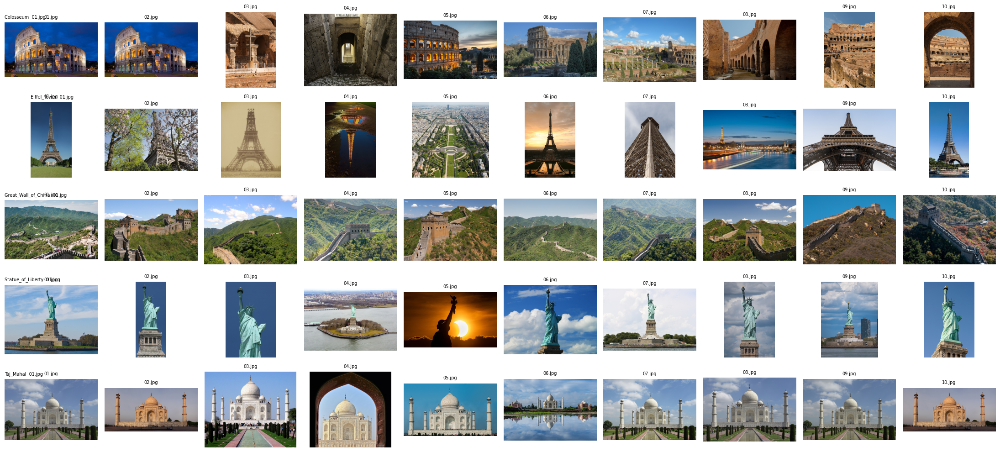

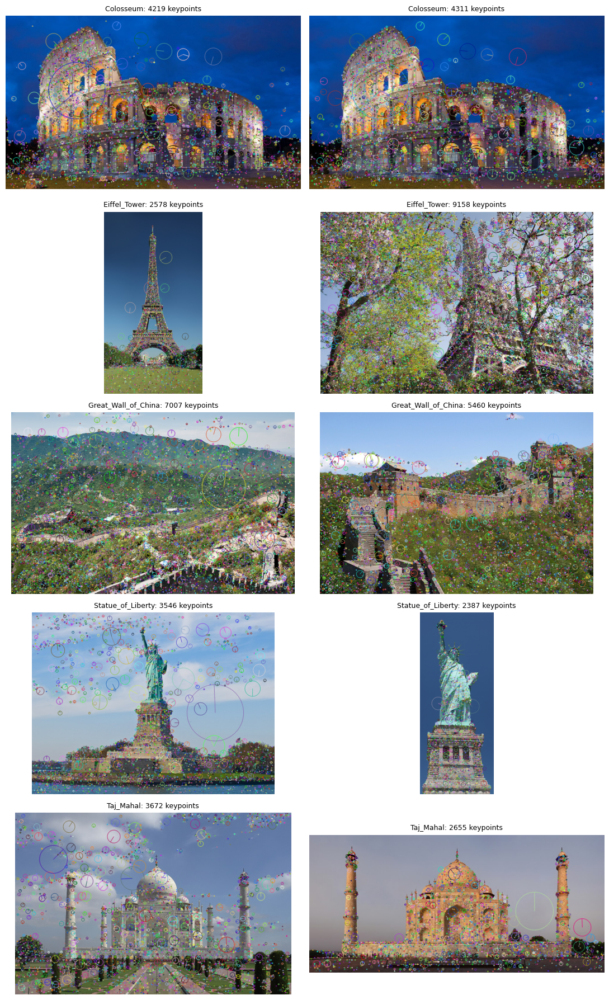

In [4]:
# Look at the database. If a picture is irrelevant (interior shot, wrong object), delete it and re-run from the "load_database" cell:
#   os.remove("landmark_db/Colosseum/03.jpg")
cols = max(len(v) for v in db.values())
fig, axes = plt.subplots(len(db), cols, figsize=(2.2 * cols, 2.0 * len(db)), squeeze=False)
for i, (name, refs) in enumerate(db.items()):
    for j in range(cols):
        ax = axes[i][j]; ax.axis("off")
        if j < len(refs):
            ax.imshow(rgb(refs[j]["img"])); ax.set_title(os.path.basename(refs[j]["path"]), fontsize=7)
    axes[i][0].set_title(f"{name}  " + os.path.basename(refs[0]["path"]), fontsize=7, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/database_overview.png", dpi=120); plt.show()

# Task 2.4: reference images with keypoints
fig, axes = plt.subplots(len(db), 2, figsize=(11, 3.6 * len(db)), squeeze=False)
for i, (name, refs) in enumerate(db.items()):
    for j in range(2):
        ax = axes[i][j]; ax.axis("off")
        r = refs[j]
        ax.imshow(rgb(cv2.drawKeypoints(r["img"], r["kp"], None, flags=RICH)))
        ax.set_title(f"{name}: {len(r['kp'])} keypoints", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/reference_keypoints.png", dpi=120); plt.show()

## Task 3: Query image processing

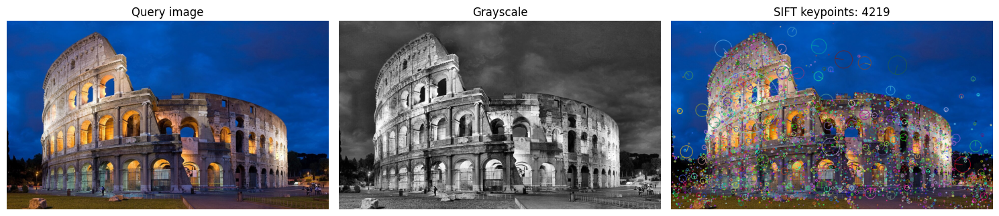

Descriptor matrix: (4219, 128)


In [5]:
def show_query(img_bgr):
    q, gray = preprocess(img_bgr)
    kp, des = extract(gray)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].imshow(rgb(q)); ax[0].set_title("Query image")
    ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale")
    ax[2].imshow(rgb(cv2.drawKeypoints(q, kp, None, flags=RICH))); ax[2].set_title(f"SIFT keypoints: {len(kp)}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    print("Descriptor matrix:", des.shape)

first = next(iter(db))
show_query(db[first][0]["img"])

## Task 4 and 5: Matching, recognition and localization

Prediction: Colosseum | keypoints=4219 | reliable matches=3409 | RANSAC inliers=3407
 Rank            Landmark  Reliable_Matches  RANSAC_Inliers
    1           Colosseum              3409            3407
    2        Eiffel_Tower                 9               4
    3 Great_Wall_of_China                 9               4
    4   Statue_of_Liberty                 9               4
    5           Taj_Mahal                 8               4


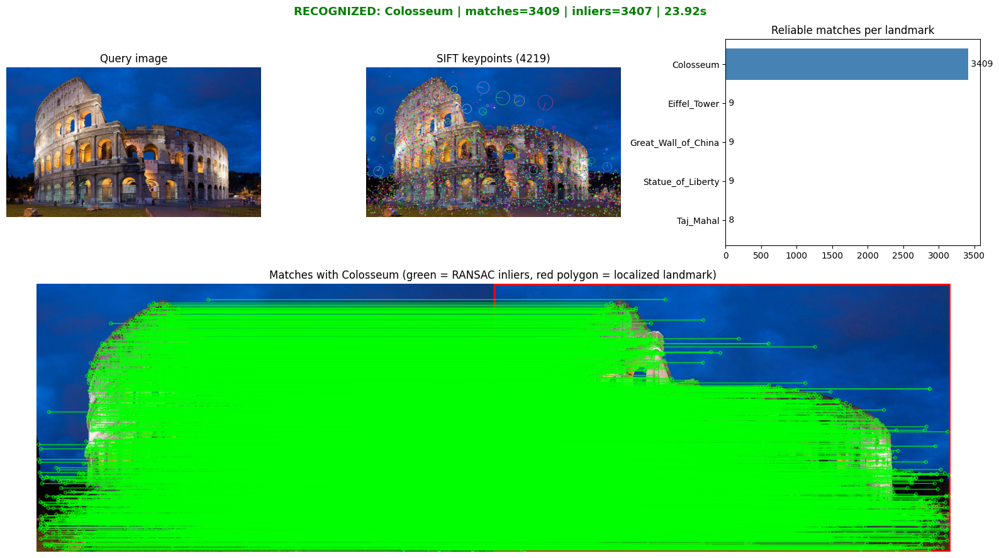

In [6]:
def ratio_matches(des_q, des_r):
    if len(des_q) < 2 or len(des_r) < 2: return []
    bf = cv2.BFMatcher(cv2.NORM_L2)                      # Brute-Force, Euclidean
    knn = bf.knnMatch(des_q, des_r, k=2)                 # k = 2
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]   # Lowe's ratio test
    best = {}                                            # one-to-one matches
    for m in good:
        if m.trainIdx not in best or m.distance < best[m.trainIdx].distance:
            best[m.trainIdx] = m
    return list(best.values())

def geometric_check(kp_q, kp_r, good, ref_shape, q_shape):
    info = dict(H=None, mask=None, inliers=0, poly=None, ok=False, msg="Not enough matches for homography")
    if len(good) < 8: return info
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH, maxIters=5000, confidence=0.995)
    if H is None:
        info["msg"] = "Homography estimation failed"; return info
    mask = mask.ravel().astype(bool)
    info.update(H=H, mask=mask, inliers=int(mask.sum()))
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H).reshape(-1, 2)      # project 4 reference corners
    info["poly"] = poly
    area = cv2.contourArea(poly.astype(np.float32)); qa = q_shape[0] * q_shape[1]
    convex = cv2.isContourConvex(poly.astype(np.float32).reshape(-1, 1, 2))
    if info["inliers"] < MIN_INLIERS:        info["msg"] = "Too few RANSAC inliers - transformation unreliable"
    elif not convex:                         info["msg"] = "Projected region not convex - transformation unreliable"
    elif not (0.01 * qa < area < 10 * qa):   info["msg"] = "Projected region has implausible size - transformation unreliable"
    else:                                    info.update(ok=True, msg="Geometric verification succeeded")
    return info

def recognize(query_bgr, db, exclude=()):
    t0 = time.perf_counter()
    q, gray = preprocess(query_bgr)
    kp_q, des_q = extract(gray)
    per = {}
    for name, refs in db.items():
        best = None
        for r in refs:
            if r["path"] in exclude: continue
            good = ratio_matches(des_q, r["des"])
            geo = geometric_check(kp_q, r["kp"], good, r["img"].shape, q.shape)
            if best is None or (geo["inliers"], len(good)) > (best["geo"]["inliers"], len(best["good"])):
                best = dict(ref=r, good=good, geo=geo)
        if best: per[name] = best
    ranking = sorted(per.items(), key=lambda kv: (kv[1]["geo"]["inliers"], len(kv[1]["good"])), reverse=True)
    top_name, top = ranking[0]
    second = ranking[1][1]["geo"]["inliers"] if len(ranking) > 1 else 0
    n_good, n_inl = len(top["good"]), top["geo"]["inliers"]
    if n_good < MIN_GOOD:               pred, reason = "Unknown", f"only {n_good} reliable matches (< {MIN_GOOD})"
    elif not top["geo"]["ok"]:          pred, reason = "Unknown", top["geo"]["msg"]
    elif n_inl < MARGIN * second:       pred, reason = "Unknown", f"ambiguous: {n_inl} inliers vs runner-up {second}"
    else:                               pred, reason = top_name, "accepted"
    return dict(query_img=q, kp_q=kp_q, ranking=ranking, top_name=top_name, top=top, pred=pred,
                recognized=(pred != "Unknown"), reason=reason, n_kp=len(kp_q), n_good=n_good,
                n_inliers=n_inl, time=time.perf_counter() - t0)

def visualize(res, save_path=None, show=True, title_prefix=""):
    q, kp_q, top = res["query_img"], res["kp_q"], res["top"]
    r, geo = top["ref"], top["geo"]
    q_poly = q.copy()
    if geo["ok"] and res["recognized"]:
        cv2.polylines(q_poly, [geo["poly"].astype(np.int32).reshape(-1, 1, 2)], True, (0, 0, 255), 5)
    sw = [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in top["good"]]
    mask = geo["mask"].astype(int).tolist() if geo["mask"] is not None else None
    match_img = cv2.drawMatches(r["img"], r["kp"], q_poly, kp_q, sw, None, matchColor=(0, 255, 0), matchesMask=mask,
                                flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
    fig = plt.figure(figsize=(16, 9)); gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.3])
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(rgb(q)); ax.set_title("Query image"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(rgb(cv2.drawKeypoints(q, kp_q, None, flags=RICH))); ax.set_title(f"SIFT keypoints ({res['n_kp']})"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 2])
    names = [n for n, _ in res["ranking"]][::-1]; vals = [len(d["good"]) for _, d in res["ranking"]][::-1]
    ax.barh(names, vals, color="steelblue"); ax.set_title("Reliable matches per landmark")
    for i, v in enumerate(vals): ax.text(v, i, f" {v}", va="center")
    ax = fig.add_subplot(gs[1, :]); ax.imshow(rgb(match_img)); ax.axis("off")
    ax.set_title(f"Matches with {res['top_name']} (green = RANSAC inliers, red polygon = localized landmark)")
    if res["recognized"]:
        status = f"RECOGNIZED: {res['pred']} | matches={res['n_good']} | inliers={res['n_inliers']} | {res['time']:.2f}s"
    else:
        status = f"REJECTED (unknown) - {res['reason']} | matches={res['n_good']} | {res['time']:.2f}s"
        if not geo["ok"]: status += f"\n{geo['msg']}"
    fig.suptitle(title_prefix + status, fontsize=13, color="green" if res["recognized"] else "red", fontweight="bold")
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True); fig.savefig(save_path, dpi=120)
    plt.show() if show else plt.close(fig)

# demo: held-out image of the first landmark
held = db[first][0]
res = recognize(held["img"], db, exclude={held["path"]})
print(f"Prediction: {res['pred']} | keypoints={res['n_kp']} | reliable matches={res['n_good']} | RANSAC inliers={res['n_inliers']}")
print(pd.DataFrame([dict(Rank=i + 1, Landmark=n, Reliable_Matches=len(d["good"]), RANSAC_Inliers=d["geo"]["inliers"])
                    for i, (n, d) in enumerate(res["ranking"])]).to_string(index=False))
visualize(res, f"{OUT_DIR}/demo_result.png")

## Task 6: Performance evaluation

In [7]:
def make_variants(img):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1]); nw, nh = int(h * s + w * c), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    rotated = cv2.warpAffine(img, M, (nw, nh))
    resized = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    dark = cv2.convertScaleAbs(img, alpha=0.4, beta=0)
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[0.10 * w, 0.06 * h], [0.92 * w, 0], [w, h], [0, 0.94 * h]])
    view = cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))
    return [("Original", img), ("Rotated (30 deg)", rotated), ("Resized (50%)", resized),
            ("Low brightness", dark), ("Different viewpoint", view)]

rows = []; examples = {}
def log(cond, true, res, landmark):
    rows.append({"Landmark": landmark, "Condition": cond, "True": true, "Predicted": res["pred"],
                 "Keypoints": res["n_kp"], "Reliable Matches": res["n_good"], "RANSAC Inliers": res["n_inliers"],
                 "Decision": "Recognized" if res["recognized"] else "Rejected",
                 "Correct": "Yes" if res["pred"] == true else "No", "Time (s)": round(res["time"], 3)})
    tag = f"{landmark}_{cond}".replace(" ", "_").replace("(", "").replace(")", "").replace("%", "pct")
    visualize(res, f"{OUT_DIR}/figs/{tag}.png", show=False, title_prefix=f"[{landmark} | {cond}] ")
    examples[(landmark, cond)] = res

for name, refs in db.items():
    held = refs[0]
    for cond, img in make_variants(held["img"]):
        log(cond, name, recognize(img, db, exclude={held["path"]} if HOLD_OUT else set()), name)

unk_files = sorted(glob.glob(f"{UNKNOWN_DIR}/**/*.jpg", recursive=True))
if unk_files:
    for f in unk_files:
        log("Unknown landmark", "Unknown", recognize(cv2.imread(f), db), os.path.basename(os.path.dirname(f)))
else:   # fallback: leave one whole landmark out of the database
    name = next(iter(db))
    log("Unknown landmark", "Unknown", recognize(db[name][0]["img"], db, exclude={r["path"] for r in db[name]}), f"{name} (left out)")

df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/results_table.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
display(df)

df["ok"] = df["Correct"] == "Yes"
print(f"\nOverall accuracy: {df.ok.mean()*100:.1f}%  ({df.ok.sum()}/{len(df)})")
print(f"Mean processing time: {df['Time (s)'].mean():.3f}s")
display(df.groupby("Condition").agg(Accuracy=("ok", "mean"), Mean_Matches=("Reliable Matches", "mean"),
        Mean_Inliers=("RANSAC Inliers", "mean"), Mean_Time_s=("Time (s)", "mean")).round(2))

,Landmark,Condition,True,Predicted,Keypoints,Reliable Matches,RANSAC Inliers,Decision,Correct,Time (s)
0,Colosseum,Original,Colosseum,Colosseum,4219,3409,3407,Recognized,Yes,22.916
1,Colosseum,Rotated (30 deg),Colosseum,Colosseum,4742,2170,2164,Recognized,Yes,25.535
2,Colosseum,Resized (50%),Colosseum,Colosseum,1302,875,873,Recognized,Yes,6.583
3,Colosseum,Low brightness,Colosseum,Colosseum,3750,2781,2774,Recognized,Yes,20.618
4,Colosseum,Different viewpoint,Colosseum,Colosseum,5021,2373,2356,Recognized,Yes,26.629
5,Eiffel_Tower,Original,Eiffel_Tower,Eiffel_Tower,2578,30,23,Recognized,Yes,13.667
6,Eiffel_Tower,Rotated (30 deg),Eiffel_Tower,Eiffel_Tower,3174,26,21,Recognized,Yes,17.324
7,Eiffel_Tower,Resized (50%),Eiffel_Tower,Unknown,604,4,0,Rejected,No,3.022
8,Eiffel_Tower,Low brightness,Eiffel_Tower,Eiffel_Tower,2110,25,21,Recognized,Yes,11.161
9,Eiffel_Tower,Different viewpoint,Eiffel_Tower,Eiffel_Tower,3378,23,19,Recognized,Yes,18.019



Overall accuracy: 86.2%  (25/29)
Mean processing time: 18.654s


,Accuracy,Mean_Matches,Mean_Inliers,Mean_Time_s
Condition,,,,
Different viewpoint,0.8,893.40,877.20,26.74
Low brightness,1.0,978.60,966.60,18.44
Original,0.8,1269.80,1254.20,22.21
Resized (50%),0.6,359.00,354.00,6.34
Rotated (30 deg),1.0,802.40,785.40,23.89
Unknown landmark,1.0,7.75,2.25,13.21


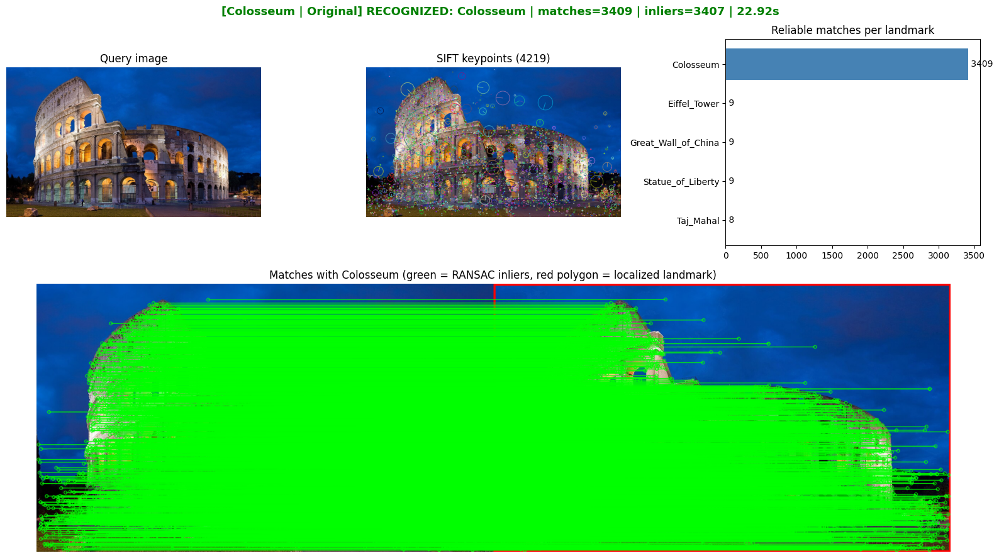

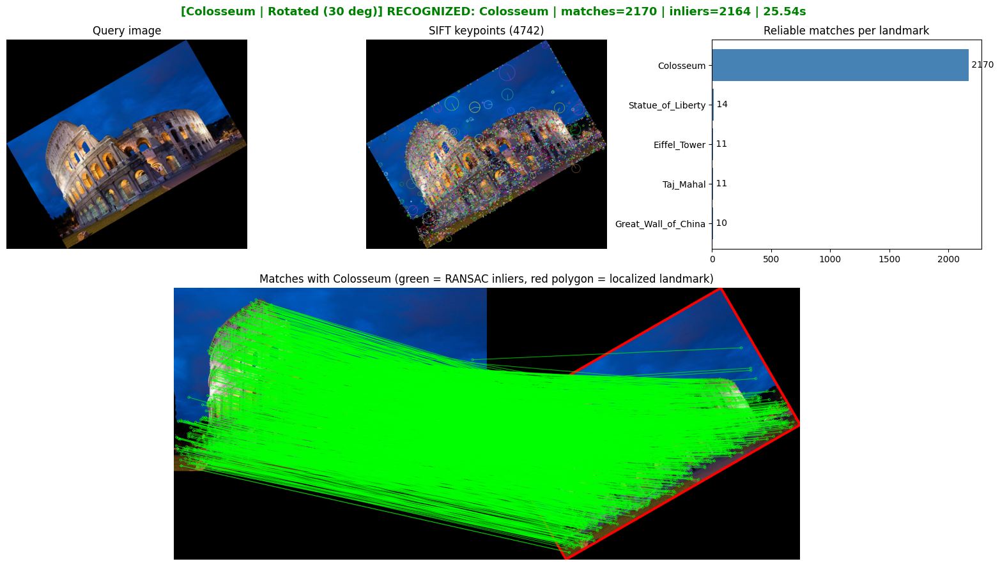

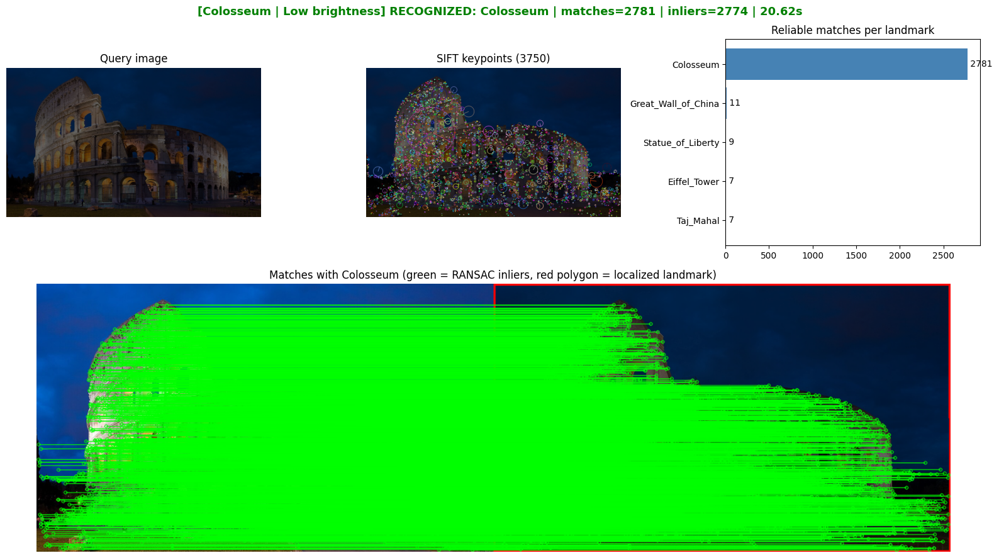

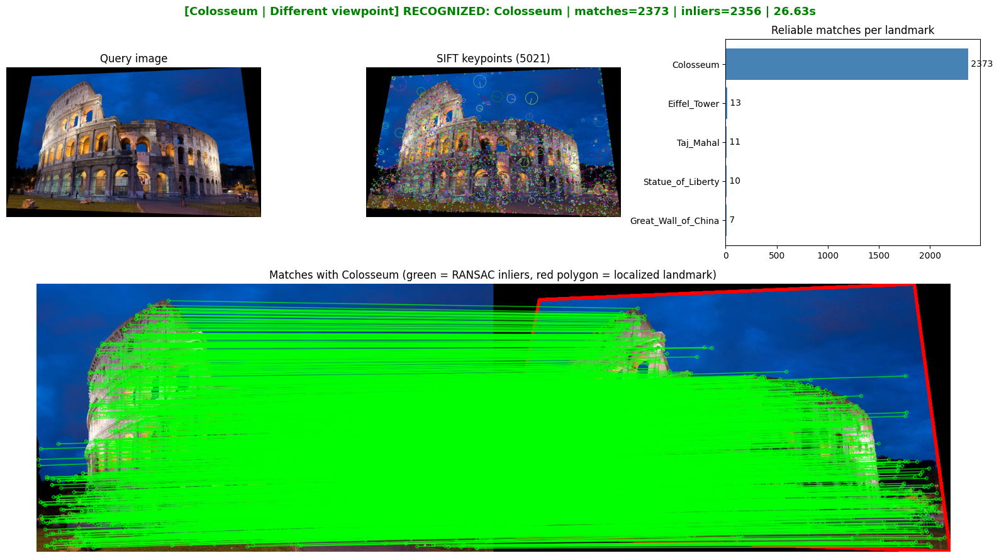

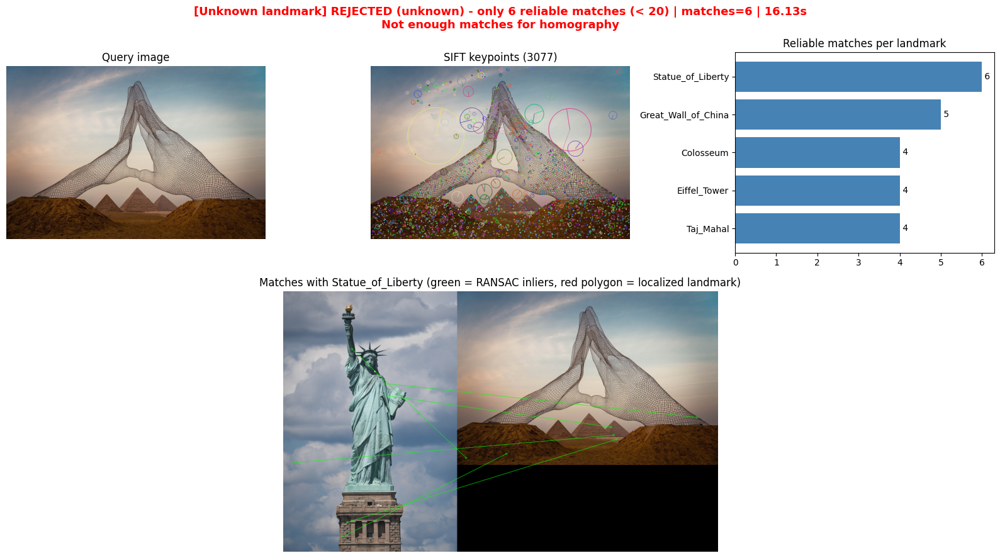

In [8]:
# Screenshots for the report: one example per condition (all figures are also saved in results/figs/)
for key in [(first, "Original"), (first, "Rotated (30 deg)"), (first, "Low brightness"), (first, "Different viewpoint")]:
    if key in examples: visualize(examples[key], show=True, title_prefix=f"[{key[0]} | {key[1]}] ")
unk = [k for k in examples if k[1] == "Unknown landmark"]
if unk: visualize(examples[unk[0]], show=True, title_prefix="[Unknown landmark] ")

Saving download.jfif to download.jfif
download.jfif -> Unknown | matches 4 | inliers 0 | only 4 reliable matches (< 20)


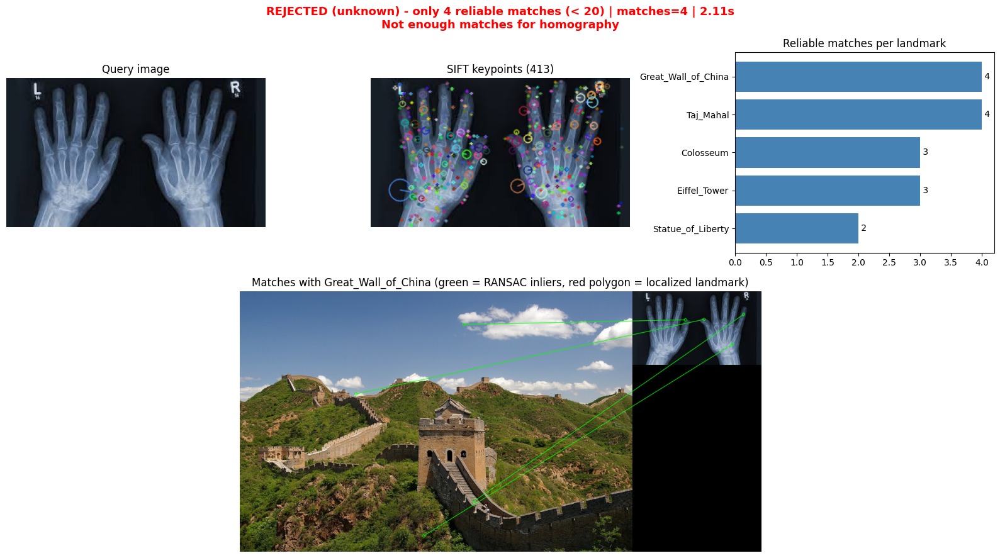

In [9]:
try:
    from google.colab import files
    up = files.upload()
    for fn in up:
        r = recognize(cv2.imread(fn), db)
        print(fn, "->", r["pred"], "| matches", r["n_good"], "| inliers", r["n_inliers"], "|", r["reason"])
        visualize(r)
except ImportError:
    print("Not running in Colab: set the path manually, e.g. recognize(cv2.imread('photo.jpg'), db)")